# Notebook 3 — Demand Modeling

Three models are trained to predict `Units_Sold` and compared on the same unseen test period:

1. Linear Regression (baseline)
2. Random Forest
3. XGBoost

The best one is saved as a single pipeline (preprocessing + model) for the optimiser and the app.

In [1]:
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sys.path.insert(0, "../src")
import pricing_engine as engine

In [2]:
df = pd.read_csv("../data/processed_restaurant_sales_data.csv.gz")
df["Date"] = pd.to_datetime(df["Date"])

print("Shape:", df.shape)

Shape: (174960, 46)


In [3]:
target = "Units_Sold"
categorical_features = engine.CATEGORICAL_FEATURES
numerical_features = engine.NUMERICAL_FEATURES

X = df[categorical_features + numerical_features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (174960, 37)
y shape: (174960,)


In [4]:
# Chronological train/test split: first 80% of dates for training, last 20% for testing
unique_dates = np.sort(df["Date"].unique())
split_date = unique_dates[int(len(unique_dates) * 0.80)]

train_mask = df["Date"] < split_date
test_mask = df["Date"] >= split_date

X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]

print("Split date:", pd.Timestamp(split_date).date())
print("Training observations:", len(X_train))
print("Testing observations :", len(X_test))

Split date: 2026-05-08
Training observations: 139920
Testing observations : 35040


In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("numerical", "passthrough", numerical_features),
    ],
    verbose_feature_names_out=False,
)
preprocessor.set_output(transform="pandas")   # keep column names, so the model knows which column is which

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape :", X_test_processed.shape)

Processed training shape: (139920, 115)
Processed testing shape : (35040, 115)


In [6]:
def evaluate(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    print(name)
    print("-" * len(name))
    print("MAE :", round(mae, 3))
    print("RMSE:", round(rmse, 3))
    print("R2  :", round(r2, 3))
    return {"Model": name, "MAE": mae, "RMSE": rmse, "R2": r2}

results = []

## Model 1: Linear Regression

In [7]:
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

linear_pred = linear_model.predict(X_test_processed)
results.append(evaluate("Linear Regression", y_test, linear_pred))

Linear Regression
-----------------
MAE : 6.364
RMSE: 8.927
R2  : 0.876


## Model 2: Random Forest

In [8]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
)
rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)
results.append(evaluate("Random Forest", y_test, rf_pred))

Random Forest
-------------
MAE : 4.97
RMSE: 6.811
R2  : 0.928


## Model 3: XGBoost

One business rule is built into the model: **predicted demand may never go up when our own price goes
up.** Without it, a tree model can learn small random bumps from noisy data ("a higher price sells
more") and the optimiser would chase them. The rule is applied to every feature that rises with our
price (`monotone_constraints`).

In [9]:
price_features = engine.PRICE_MONOTONE_FEATURES
print("Price features with the 'never increases demand' rule:", price_features)

xgb_model = XGBRegressor(
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    monotone_constraints={feature: -1 for feature in price_features},
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X_train_processed, y_train)

xgb_pred = xgb_model.predict(X_test_processed)
results.append(evaluate("XGBoost", y_test, xgb_pred))

Price features with the 'never increases demand' rule: ['Selling_Price', 'Price_Index', 'Competitor_Price_Gap', 'Competitor_Price_Ratio']


XGBoost
-------
MAE : 4.632
RMSE: 6.32
R2  : 0.938


## Model comparison

In [10]:
model_comparison = pd.DataFrame(results).sort_values("R2", ascending=False).reset_index(drop=True)
model_comparison.round(3)

,Model,MAE,RMSE,R2
0,XGBoost,4.632,6.320,0.938
1,Random Forest,4.970,6.811,0.928
2,Linear Regression,6.364,8.927,0.876


In [11]:
model_comparison.round(3).to_csv("../data/model_performance_summary.csv", index=False)
print("Model performance summary saved.")

best = model_comparison.iloc[0]
print(f"Best model: {best['Model']} (R2 = {best['R2']:.3f}, MAE = {best['MAE']:.2f} units)")

Model performance summary saved.
Best model: XGBoost (R2 = 0.938, MAE = 4.63 units)


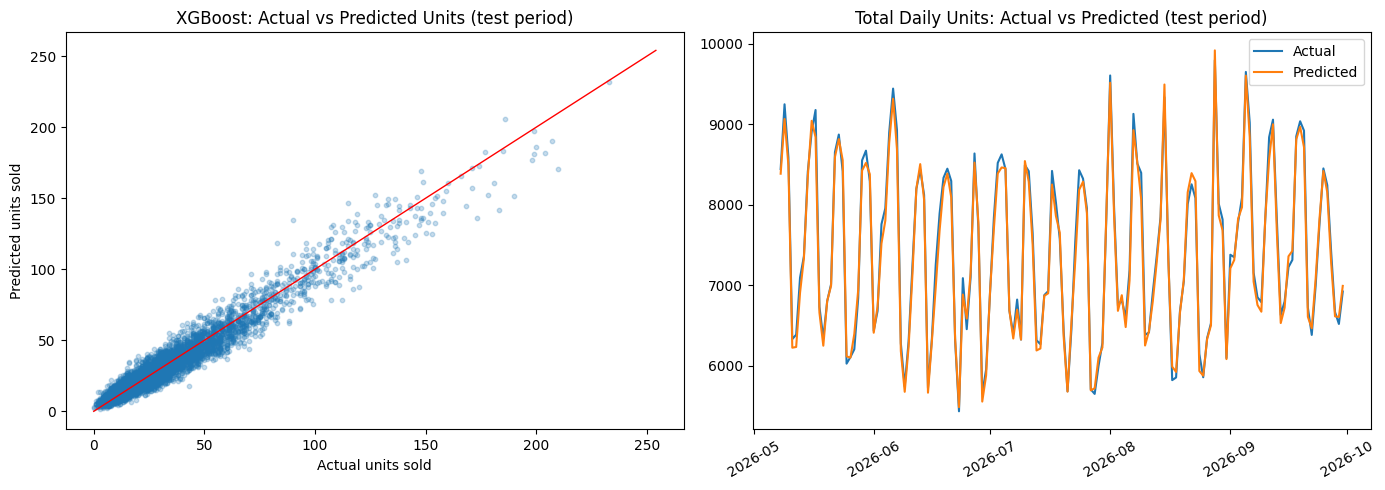

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sample = np.random.RandomState(42).choice(len(y_test), 6000, replace=False)
axes[0].scatter(y_test.to_numpy()[sample], xgb_pred[sample], alpha=0.25, s=10)
limit = max(y_test.max(), xgb_pred.max())
axes[0].plot([0, limit], [0, limit], color="red", linewidth=1)
axes[0].set_title("XGBoost: Actual vs Predicted Units (test period)")
axes[0].set_xlabel("Actual units sold")
axes[0].set_ylabel("Predicted units sold")

test_dates = df.loc[test_mask, "Date"]
actual_daily = y_test.groupby(test_dates).sum()
predicted_daily = pd.Series(xgb_pred, index=y_test.index).groupby(test_dates).sum()
axes[1].plot(actual_daily.index, actual_daily.values, label="Actual")
axes[1].plot(predicted_daily.index, predicted_daily.values, label="Predicted")
axes[1].set_title("Total Daily Units: Actual vs Predicted (test period)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()

plt.tight_layout()
plt.show()

## Final pipeline

The preprocessor and the XGBoost model are saved together, so the app can pass raw scenario columns
straight in.

In [13]:
xgboost_pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", xgb_model)])
xgboost_pipeline.fit(X_train, y_train)

final_pred = xgboost_pipeline.predict(X_test)
final = evaluate("Final XGBoost Pipeline", y_test, final_pred)
print("\nModel input features:", len(xgboost_pipeline.feature_names_in_))

Final XGBoost Pipeline
----------------------
MAE : 4.632
RMSE: 6.32
R2  : 0.938

Model input features: 37


### Does the price rule hold?

For 2,000 test rows the selling price is moved from -10% to +10% of the base price. Predicted demand
should fall (or stay flat) at every step, for every row.

In [14]:
check = X_test.sample(2000, random_state=42).copy()
ladder = {}
for level in [0.90, 0.95, 1.00, 1.05, 1.10]:
    scenario = check.copy()
    scenario["Selling_Price"] = (scenario["Base_Price"] * level).round()
    scenario = engine.add_price_features(scenario)
    ladder[level] = xgboost_pipeline.predict(scenario[list(xgboost_pipeline.feature_names_in_)])

ladder = pd.DataFrame(ladder)
violations = (ladder.diff(axis=1).iloc[:, 1:] > 1e-6).any(axis=1).sum()

print("Average predicted units at each price level:")
print(ladder.mean().round(2).to_string())
print(f"\nRows where a higher price predicts MORE demand: {violations} of {len(ladder)}")
print(f"Implied price elasticity (-10% to +10%): {np.log(ladder[1.10].mean() / ladder[0.90].mean()) / np.log(1.10 / 0.90):.2f}")

Average predicted units at each price level:
0.90    33.040001
0.95    31.059999
1.00    29.000000
1.05    27.309999
1.10    25.770000

Rows where a higher price predicts MORE demand: 0 of 2000
Implied price elasticity (-10% to +10%): -1.24


## Save the model

In [15]:
joblib.dump(xgboost_pipeline, "../models/xgboost_demand_model.pkl")
print("Final XGBoost pipeline saved successfully.")

loaded_model = joblib.load("../models/xgboost_demand_model.pkl")
print("Saved model loaded successfully:", type(loaded_model))
print("Predictions identical after reload:", bool(np.allclose(loaded_model.predict(X_test.head(500)), final_pred[:500])))

Final XGBoost pipeline saved successfully.
Saved model loaded successfully: <class 'sklearn.pipeline.Pipeline'>
Predictions identical after reload: True
